# Denoising Diffusion Probabilistic Models (DDPM)

**Paper:** Ho, J., Jain, A., & Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS 2020. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)

This notebook implements DDPM from scratch in PyTorch:
1. Forward diffusion: adding Gaussian noise with a linear β schedule (T = 1000, β from 1e-4 to 0.02, as in the paper)
2. A compact U-Net that predicts the noise, with sinusoidal timestep embeddings and self-attention at 16×16
3. Training with the paper's simplified noise-prediction loss, with an exponential moving average (EMA) of the weights
4. Sampling: 1000 reverse steps starting from pure noise

It trains on all 60,000 FashionMNIST training images, resized to 32×32. The Summary at the end says what this run found.

## 1. Setup and Imports

In [1]:
import os
# Deterministic cuBLAS kernels; must be set before torch is imported
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import atexit
import contextlib
import copy
import io
import math
import shutil
import tempfile
import time
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
# Deterministic GPU kernels where PyTorch has them (warn instead of failing for the rest)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings('ignore', message='.*deterministic.*')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## 2. Hyperparameters

T, the β schedule, the learning rate and the batch size follow the paper's CIFAR10 settings (Section 4 and Appendix B). The model is much smaller and trains for far fewer steps.

In [2]:
T = 1000            # diffusion steps
IMG_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 128
EPOCHS = 25
LR = 2e-4
BASE_CH = 32
GROUPS = 8
BETA_START = 1e-4
BETA_END = 0.02
EMA_DECAY = 0.999   # the paper uses 0.9999 over 800k steps; this run is ~12k steps

## 3. Forward Diffusion Process

The forward process adds Gaussian noise according to a variance schedule {beta_t}.
We can sample x_t directly from x_0 in closed form:

q(x_t | x_0) = N(x_t; sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)

where alpha_bar_t = prod(1 - beta_s) for s=1..t

In [3]:
def linear_beta_schedule(timesteps, beta_start, beta_end):
    return torch.linspace(beta_start, beta_end, timesteps)

betas = linear_beta_schedule(T, BETA_START, BETA_END).to(device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

print(f"alpha_bar at t = T: {alphas_cumprod[-1].item():.2e} (close to 0, so x_T is almost pure noise)")

def q_sample(x_0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_alpha = sqrt_alphas_cumprod.gather(0, t).view(-1, 1, 1, 1)
    sqrt_one_minus = sqrt_one_minus_alphas_cumprod.gather(0, t).view(-1, 1, 1, 1)
    return sqrt_alpha * x_0 + sqrt_one_minus * noise

alpha_bar at t = T: 4.04e-05 (close to 0, so x_T is almost pure noise)


## 4. Dataset and DataLoader

In [4]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])
# Download quietly (no progress bars in the saved notebook)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    full_dataset = datasets.FashionMNIST(root=tempfile.gettempdir(), train=True, download=True,
                                         transform=transform)

# Transform all 60,000 images once and keep them as one tensor, so no DataLoader workers are needed
images = torch.stack([full_dataset[i][0] for i in range(len(full_dataset))])
dataset = TensorDataset(images)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True,
                        generator=torch.Generator().manual_seed(SEED))
print(f"Dataset size: {len(dataset)}, image tensor: {tuple(images.shape)}, batches per epoch: {len(dataloader)}")

Dataset size: 60000, image tensor: (60000, 1, 32, 32), batches per epoch: 468


## 5. Visualize Forward Diffusion

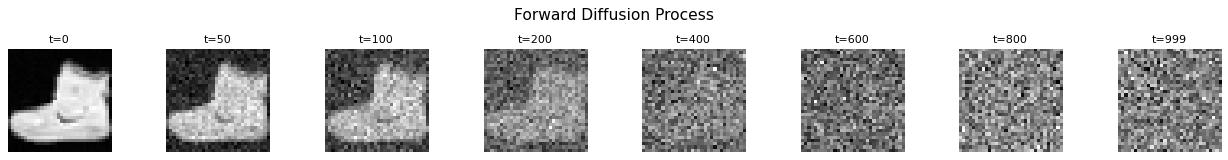

In [5]:
sample = dataset[0][0]
sample = sample.unsqueeze(0).to(device)

fig, axes = plt.subplots(1, 8, figsize=(16, 2))
timesteps_to_show = [0, 50, 100, 200, 400, 600, 800, 999]
for ax, t_val in zip(axes, timesteps_to_show):
    t_tensor = torch.tensor([t_val]).to(device)
    noisy = q_sample(sample, t_tensor)
    img = noisy.squeeze(0).squeeze(0).cpu().numpy()
    img = (img + 1) / 2
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val}', fontsize=10)
    ax.axis('off')
plt.suptitle('Forward Diffusion Process', fontsize=14)
plt.tight_layout()
plt.show()

## 6. U-Net Denoiser Architecture

The U-Net predicts the noise ε_θ(x_t, t) from the noisy image x_t and the timestep t.
Key components:
- Sinusoidal time embedding → MLP → added inside every ResBlock
- ResBlocks: GroupNorm → SiLU → Conv, twice, with a skip connection
- Spatial self-attention only at the 16×16 resolution, as in the paper (every position attends to every other position)
- Down/up path at 32×32, 16×16 and 8×8 with skip connections between them

In [6]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        return embeddings

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_ch))
        if in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1)
        else:
            self.skip = nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_mlp(t_emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class AttentionBlock(nn.Module):
    """Spatial self-attention: each of the H*W positions attends to all positions."""
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        self.heads = heads
        self.scale = (channels // heads) ** -0.5

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        qkv = self.qkv(h).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]                      # (B, heads, d, N)
        attn = torch.einsum('bhdn,bhdm->bhnm', q, k) * self.scale      # (B, heads, N, N)
        attn = attn.softmax(dim=-1)                                    # over the attended positions m
        out = torch.einsum('bhnm,bhdm->bhdn', attn, v)                 # (B, heads, d, N)
        out = out.reshape(B, C, H, W)
        return x + self.proj(out)


class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)
    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, base_ch=32, groups=8):
        super().__init__()
        time_dim = base_ch * 4
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(base_ch),
            nn.Linear(base_ch, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        c1, c2, c3 = base_ch, base_ch * 2, base_ch * 4

        self.input_conv = nn.Conv2d(in_channels, c1, 3, padding=1)

        # Encoder
        self.enc1_res = ResBlock(c1, c1, time_dim, groups)
        self.enc1_down = Downsample(c1)
        self.enc2_res = ResBlock(c1, c2, time_dim, groups)
        self.enc2_attn = AttentionBlock(c2)   # 16x16
        self.enc2_down = Downsample(c2)
        self.enc3_res = ResBlock(c2, c3, time_dim, groups)

        # Bottleneck
        self.mid1 = ResBlock(c3, c3, time_dim, groups)
        self.mid2 = ResBlock(c3, c3, time_dim, groups)

        # Decoder
        self.dec3_res1 = ResBlock(c3 + c3, c3, time_dim, groups)
        self.dec3_up = Upsample(c3)
        self.dec2_res1 = ResBlock(c3 + c2, c2, time_dim, groups)
        self.dec2_attn1 = AttentionBlock(c2)  # 16x16
        self.dec2_up = Upsample(c2)
        self.dec1_res1 = ResBlock(c2 + c1, c1, time_dim, groups)

        self.final_norm = nn.GroupNorm(groups, c1)
        self.final_conv = nn.Conv2d(c1, in_channels, 3, padding=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        x = self.input_conv(x)

        # Encoder
        x = self.enc1_res(x, t_emb)
        skip1 = x
        x = self.enc1_down(x)

        x = self.enc2_res(x, t_emb)
        x = self.enc2_attn(x)
        skip2 = x
        x = self.enc2_down(x)

        x = self.enc3_res(x, t_emb)
        skip3 = x

        # Bottleneck
        x = self.mid1(x, t_emb)
        x = self.mid2(x, t_emb)

        # Decoder
        x = torch.cat([x, skip3], dim=1)
        x = self.dec3_res1(x, t_emb)
        x = self.dec3_up(x)

        x = torch.cat([x, skip2], dim=1)
        x = self.dec2_res1(x, t_emb)
        x = self.dec2_attn1(x)
        x = self.dec2_up(x)

        x = torch.cat([x, skip1], dim=1)
        x = self.dec1_res1(x, t_emb)

        x = F.silu(self.final_norm(x))
        return self.final_conv(x)

model = UNet(in_channels=CHANNELS, base_ch=BASE_CH, groups=GROUPS).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net parameters: {n_params:,}")

ema_model = copy.deepcopy(model).eval()
for p in ema_model.parameters():
    p.requires_grad_(False)

U-Net parameters: 1,951,329


## 7. Training Loop

The simplified training objective (Section 3.4): L_simple = E[‖ε − ε_θ(x_t, t)‖²].
For each batch: sample random timesteps, add noise, predict the noise, take the mean squared error. After every step, an exponential moving average (EMA) of the weights is updated; the EMA model is used for sampling, as in the paper.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
losses = []
start = time.time()

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for (batch,) in dataloader:
        batch = batch.to(device)
        B = batch.shape[0]
        t = torch.randint(0, T, (B,), device=device).long()
        noise = torch.randn_like(batch)
        x_t = q_sample(batch, t, noise)
        predicted_noise = model(x_t, t)
        loss = F.mse_loss(predicted_noise, noise)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            for p_ema, p in zip(ema_model.parameters(), model.parameters()):
                p_ema.mul_(EMA_DECAY).add_(p, alpha=1 - EMA_DECAY)
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(dataloader)
    losses.append(avg_loss)
    print(f'Epoch {epoch+1}/{EPOCHS} - avg loss: {avg_loss:.4f} ({time.time() - start:.0f} s)')

print(f'Training complete: {EPOCHS * len(dataloader):,} steps')

Epoch 1/25 - avg loss: 0.0849 (64 s)


Epoch 2/25 - avg loss: 0.0421 (130 s)


Epoch 3/25 - avg loss: 0.0368 (197 s)


Epoch 4/25 - avg loss: 0.0340 (263 s)


Epoch 5/25 - avg loss: 0.0325 (329 s)


Epoch 6/25 - avg loss: 0.0312 (395 s)


... (15 outputs left out)

Epoch 22/25 - avg loss: 0.0261 (1457 s)


Epoch 23/25 - avg loss: 0.0261 (1523 s)


Epoch 24/25 - avg loss: 0.0258 (1589 s)


Epoch 25/25 - avg loss: 0.0257 (1655 s)
Training complete: 11,700 steps


## 8. Loss Curve

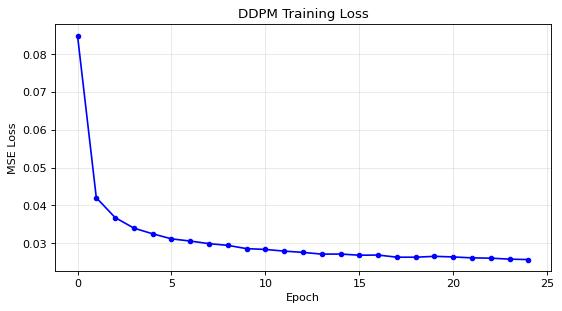

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(losses, 'b-o', markersize=4)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('DDPM Training Loss')
plt.grid(True, alpha=0.3)
plt.show()

## 9. Sampling (Reverse Diffusion Process)

Starting from pure noise x_T ~ N(0, I), we denoise step by step through all T = 1000 steps with the EMA model.
At each step the mean is μ = (1/√α_t) · (x_t − β_t / √(1 − ᾱ_t) · ε_θ(x_t, t)); for t > 0 we add noise with the fixed variance σ_t² = β̃_t (the posterior variance), one of the two choices the paper found to give similar results (Section 3.2).

In [9]:
@torch.no_grad()
def p_sample(model, x_t, t_index):
    t = torch.full((x_t.shape[0],), t_index, device=device, dtype=torch.long)
    eps_theta = model(x_t, t)

    beta_t = betas[t_index]
    sqrt_recip_alpha_t = sqrt_recip_alphas[t_index]
    sqrt_one_minus_alpha_t = sqrt_one_minus_alphas_cumprod[t_index]

    mean = sqrt_recip_alpha_t * (x_t - beta_t / sqrt_one_minus_alpha_t * eps_theta)

    if t_index > 0:
        posterior_var = posterior_variance[t_index]
        noise = torch.randn_like(x_t)
        return mean + torch.sqrt(posterior_var) * noise
    else:
        return mean

@torch.no_grad()
def sample(model, n_samples=64, channels=1, img_size=32):
    model.eval()
    x = torch.randn(n_samples, channels, img_size, img_size, device=device)
    for t in reversed(range(T)):
        x = p_sample(model, x, t)
    return x

torch.manual_seed(SEED)
samples = sample(ema_model, n_samples=64, channels=CHANNELS, img_size=IMG_SIZE)
print(f'Samples generated: {tuple(samples.shape)}')

# Simple statistics, compared with 64 real training images
real = images[:64]
print(f"Pixel mean: samples {samples.mean().item():.3f}, real {real.mean().item():.3f}")
print(f"Pixel std:  samples {samples.std().item():.3f}, real {real.std().item():.3f}")
print(f"Share of pixels near the black background (< -0.9): samples {(samples < -0.9).float().mean().item():.3f}, "
      f"real {(real < -0.9).float().mean().item():.3f}")

Samples generated: (64, 1, 32, 32)
Pixel mean: samples -0.466, real -0.425
Pixel std:  samples 0.656, real 0.683
Share of pixels near the black background (< -0.9): samples 0.523, real 0.504


## 10. Visualize Generated Samples

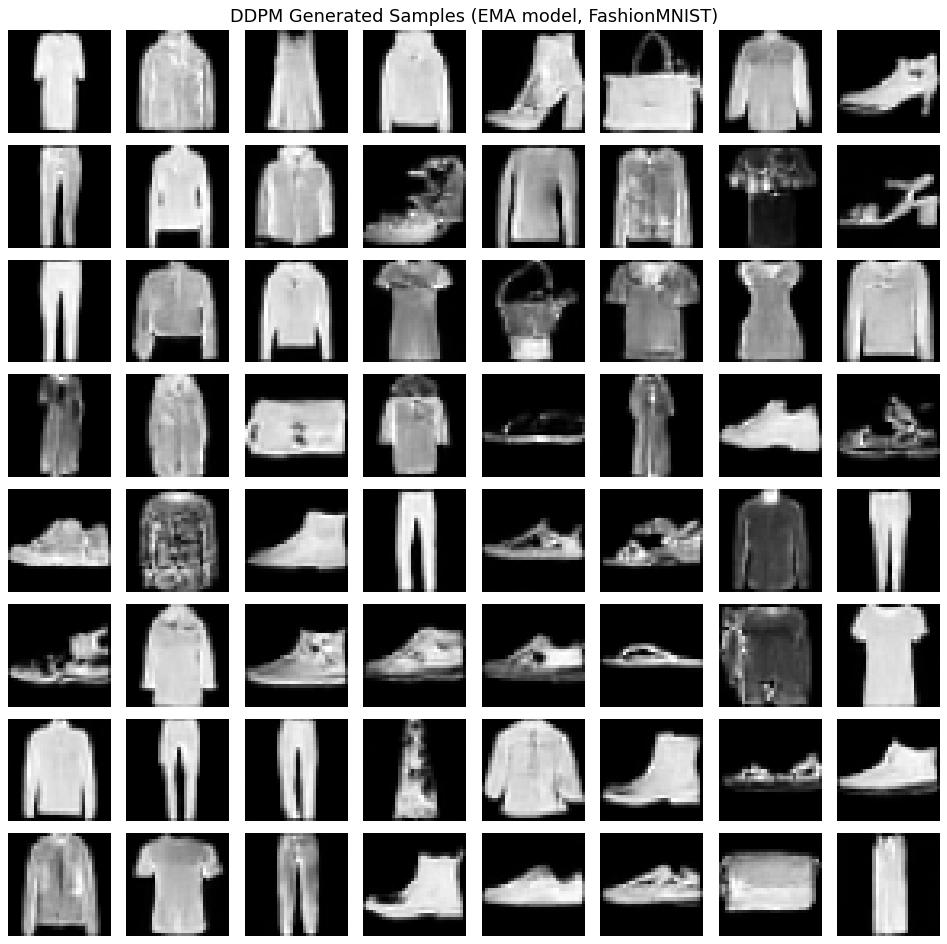

In [10]:
samples_display = (samples + 1) / 2
samples_display = samples_display.clamp(0, 1)

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    if i < samples_display.shape[0]:
        img = samples_display[i].squeeze(0).cpu().numpy()
        ax.imshow(img, cmap='gray')
    ax.axis('off')
plt.suptitle('DDPM Generated Samples (EMA model, FashionMNIST)', fontsize=16)
plt.tight_layout()
plt.show()

## 11. Summary

### What the run above shows

- **Training worked.** The U-Net (1,951,329 parameters) trained for 25 epochs on all 60,000 FashionMNIST images, 11,700 steps of batch 128. The average noise-prediction loss fell from 0.0849 in epoch 1 to 0.0257 in epoch 25, and was still falling slowly at the end.
- **The samples look like clothing.** Most of the 64 samples drawn with the EMA model through 1000 reverse steps are clearly recognisable FashionMNIST items: shirts, pullovers, trousers, dresses, sneakers, sandals, ankle boots and bags, on a black background. Some are blurry or distorted, with messy textures or broken shapes, and fine details are softer than in the real images.
- **Simple pixel statistics match the data.** Pixel mean −0.466 for the samples vs −0.425 for 64 real images, standard deviation 0.656 vs 0.683, and 52.3% vs 50.4% of pixels near the black background. These numbers only check overall brightness, not image quality; we did not compute FID.

This is a small model trained briefly on 32×32 grayscale images, so it shows the DDPM method at toy scale. The paper's 35.7M-parameter CIFAR10 model trained for 800k steps and reached FID 3.17. An earlier version of this notebook produced pure noise: its attention mixed channels instead of positions, it used only 5,000 images for 3 epochs, and with T = 100 its last step x_T still kept a lot of the image, so sampling from pure noise did not match training.
